# Module sinh đường cong Elliptic mẫu trên $\mathbb{F}_p$

> **Topic 14 – ECC Cryptanalysis · Track A (generic ECDLP search)** <br>
> **Task:** *Module sinh đường cong Elliptic đơn giản trên Fp*

### Quá trình

| Bước | Nội dung | Hàm / lớp chính |
|---|---|---|
| 0 | Nạp thư viện & lõi từ `curves.ecc`, `curves.toy_curve_gen` | `ECC`, `Point`, `D1_COLUMNS` |
| 1 | Số học cơ bản | `is_prime`, `random_prime`, `factorize`, `sqrt_mod` |
| 2 | Đường cong và phép toán nhóm | `ECC`, `Point` |
| 3 | Đếm số điểm $\#E(\mathbb{F}_p)$ | `count_points_naive`, `count_points_bsgs` |
| 4 | Phân loại, dựng bản ghi D1 | `classify`, `make_row` |
| 5 | Bộ sinh đường cong | `generate_curve` |
| 7 | Đọc/ghi CSV chuẩn D1 | `write_csv`, `load_csv` |
| 8 | Selftest và CLI | `selftest`, `main` |
| 9 | **Chạy mẫu (demo)** | sinh trọn bộ 53 curve D1 (`--full-d1`), kiểm chứng, so sánh hiệu năng |

<br>

> **Chỉ dùng cho mục đích học thuật.** Đường cong 12–48 bit là bản mẫu nhỏ để đo thuật toán tấn công và tuyệt đối không dùng làm tham số mật mã thật.

## Cơ sở lý thuyết

**1. Dạng Weierstrass ngắn.** Với $p>3$ nguyên tố:
$$E:\; y^2 = x^3 + ax + b \pmod p$$
Đường cong **không suy biến** khi biệt thức $\Delta = 4a^3 + 27b^2 
ot\equiv 0 \pmod p$ <br> (hàm `ECC.is_nonsingular()`).

**2. Nhóm các điểm.** Tập $E(\mathbb{F}_p)$ cùng điểm vô cực $\mathcal{O}$ tạo thành nhóm Abel. Phép cộng affine dùng hệ số góc $\lambda$:
- $P
e Q$: $\lambda = \dfrac{y_2-y_1}{x_2-x_1}$ ; $P=Q$: $\lambda = \dfrac{3x_1^2 + a}{2y_1}$
- $x_3 = \lambda^2 - x_1 - x_2,\quad y_3 = \lambda(x_1 - x_3) - y_1$

Nhân vô hướng $kP$ dùng **double-and-add** (độ phức tạp $O(\log k)$ phép cộng).

**3. Định lý Hasse.** $\#E(\mathbb{F}_p) = p + 1 - t$ với $|t| \le 2\sqrt{p}$. <br>
Khoảng $[p+1-2\sqrt p,\; p+1+2\sqrt p]$ chứa $\#E$ – nền tảng của việc đếm điểm bằng BSGS.

**4. Cấu trúc bậc.** Ta có: $\#E = h\cdot n$ với $n$ = bậc điểm cơ sở $G$ (bậc nhóm con), $h$ = cofactor. <br>
Với ECDLP $Q = dG$, độ khó phụ thuộc **thừa số nguyên tố lớn nhất của $n$**:
- $n$ nguyên tố, $h=1$ → `safe_prime_order` (khó nhất với tấn công generic, $\approx\sqrt n$)
- $n$ nguyên tố, $h>1$ → `cofactor_gt1`
- $n$ chỉ gồm ước nhỏ ($B$-smooth) → `smooth_order` (**Pohlig–Hellman** phá được: $\approx\sum \sqrt{q_i}$)

**5. Hai trường hợp đặc biệt cần loại** (mặc định `allow_special=False`):
- *Anomalous* $\#E = p$ → tấn công Smart/SSSA giải ECDLP trong thời gian đa thức
- *Supersingular* $\#E = p+1$ (vết $t=0$) → MOV/Frey–Rück đưa về DLP trong trường mở rộng

**6. Đếm điểm.** 
- Với $p$ nhỏ: duyệt mọi $x$ ($O(p)$). 
- Với $p$ lớn hơn: chọn điểm ngẫu nhiên $P$, tìm mọi bội của bậc $P$ trong khoảng Hasse bằng **baby-step giant-step**, chi phí $\approx O(p^{1/4})$ phép nhóm. Lặp với nhiều điểm để thu hẹp về đúng một điểm duy nhất.

*Tài liệu chi tiết xem mục "Tài liệu tham khảo" ở cuối notebook.*

## Bước 0 – Thư viện và hằng số

Cell 3 nạp các thư viện chuẩn của Python; Cell 4 tự động dò `ROOT_DIR` và import toàn bộ lõi toán học & sinh D1 từ `curves/ecc.py` và `curves/toy_curve_gen.py`:
- `ECC(a, b, p)` và `Point(E, x, y)`: lớp đường cong và điểm trên $\mathbb{F}_p$ (với thuộc tính `is_infinity` cho điểm vô cực $\mathcal{O}$).
- `D1_COLUMNS`: **thứ tự 29 cột** của CSV D1, khớp `row_schema` trong `data/schema_definition.json`.
- `_JSON_COLUMNS`, `_BOOL_COLUMNS`, `_INT_COLUMNS`: quy định cách serialize/deserialize khi ghi/đọc CSV.
- `NAIVE_COUNT_LIMIT = 2^16`: $p$ nhỏ hơn ngưỡng này thì đếm điểm trực tiếp (`count_points_naive`), ngược lại dùng BSGS (`count_points_bsgs`).

In [2]:
from __future__ import annotations
import argparse
import csv
import json
import random
import subprocess
import sys
import math, time 
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from math import gcd, isqrt
from pathlib import Path
from typing import Dict, List, Optional, Tuple

In [3]:
# Tự động dò tìm thư mục gốc dự án (chứa thư mục curves/) bất kể mở notebook từ đâu
cwd = Path.cwd().resolve()
ROOT_DIR = next((p for p in [cwd, *cwd.parents] if (p / "curves").is_dir()), cwd)
SCRIPTS_DIR = ROOT_DIR / "scripts"

for path in (str(ROOT_DIR), str(SCRIPTS_DIR)):
    if path not in sys.path:
        sys.path.insert(0, path)
from curves.ecc import *
from curves.toy_curve_gen import *

### 1a. Chạy thử: kiểm tra `is_prime` và `random_prime`

**Mục đích:** Xác minh `is_prime` với $2^{31} \pm 1$ và sinh thử một số nguyên tố ngẫu nhiên theo số bit nhập từ bàn phím.

In [4]:
# Chạy thử 
print("is_prime(2^31-1) =", is_prime(2**31 - 1), "(số nguyên tố Mersenne)")
print("is_prime(2^31+1) =", is_prime(2**31 + 1), "(chia hết cho 3)")
bit = int(input("Nhập số bit (>= 8) sinh số nguyên tố ngẫu nhiên: "))
p = random_prime(random.Random(1), bit)
print(f"random_prime {bit} bit:", p, "| số bit =", bit)

is_prime(2^31-1) = True (số nguyên tố Mersenne)
is_prime(2^31+1) = False (chia hết cho 3)
random_prime 9 bit: 433 | số bit = 9


### 1b. Phân tích thừa số: chia thử + Pollard's $\rho$
Cần phân tích $\#E$ ($\le 2^{49}$) và $n$ để phân loại đường cong.
1. **Chia thử** các ước $<5000$ (loại nhanh ước nhỏ).
2. Phần còn lại: nếu nguyên tố → xong. <br>
Ngược lại dùng **Pollard's $\rho$ (Floyd)**: dãy $x_{i+1} = x_i^2 + c \bmod n$, con trỏ "rùa–thỏ" $x, y$ và $\gcd(|x-y|, n)$ cho ước thực sự sau khoảng $\sqrt{q}$ bước ($q$ = ước nhỏ nhất).
3. Gọi đệ quy cho đến khi mọi thừa số đều nguyên tố.

`_pollard_rho` khởi tạo `random.Random(n)` ⇒ kết quả **tất định theo $n$**.

### 1b (chạy thử). Kiểm tra hàm phân tích thừa số `factorize`

**Mục đích:** Kiểm tra `factorize` trên các hợp số và số nguyên tố lớn (Mersenne $2^{31}-1$) cùng kiểm tra tương tác từ bàn phím.

In [5]:
# Chạy thử 
for v in (2**31 - 1, 600851475143, 999999000001 * 3):
    f = factorize(v)
    print(f"{v} = {f}   kiểm tra nhân lại:", math.prod(q**e for q, e in f.items()) == v)
    
num = int(input("Nhập số nguyên dương (>= 1) để phân tích thừa số nguyên tố: "))
f = factorize(num)
print(f"{num} = {f}   kiểm tra nhân lại:", math.prod(q**e for q, e in f.items()) == num)    

2147483647 = {2147483647: 1}   kiểm tra nhân lại: True
600851475143 = {71: 1, 839: 1, 1471: 1, 6857: 1}   kiểm tra nhân lại: True
2999997000003 = {3: 1, 999999000001: 1}   kiểm tra nhân lại: True
9 = {3: 2}   kiểm tra nhân lại: True


### 1c. Chạy thử: kiểm tra `sqrt_mod` trên hai nhánh $p \equiv 1$ và $p \equiv 3 \pmod 4$

**Mục đích:** Xác minh Tonelli–Shanks hoạt động đúng cho mọi thặng dư bậc hai (và trả về `None` cho phi thặng dư) với $p=41$ và $p=43$, kèm kiểm tra tương tác từ bàn phím.

In [6]:
# Chạy thử: p=41 ≡ 1 (mod 4) -> bắt buộc đi nhánh Tonelli–Shanks; p=43 ≡ 3 (mod 4) -> nhánh tắt
for p in (41, 43):
    squares = {x * x % p for x in range(1, p)}
    ok = all((sqrt_mod(n, p) ** 2) % p == n for n in squares)
    none_ok = all(sqrt_mod(n, p) is None for n in range(1, p) if n not in squares)
    print(f"p={p} (p%4={p % 4}): căn đúng cho mọi thặng dư = {ok}; trả None cho phi thặng dư = {none_ok}")

num = int(input("Nhập số nguyên dương (>= 1) để kiểm tra căn bậc hai modulo p: "))
p = int(input("Nhập số nguyên tố p lẻ: "))
if not is_prime(p) or p < 3:
    print(f"p={p} không phải số nguyên tố lẻ >= 3")
else:   
    sqrt = sqrt_mod(num, p)
    if sqrt is None:
        print(f"{num} không có căn bậc hai modulo {p}")
    else:
        print(f"Căn bậc hai của {num} modulo {p} là {sqrt} (kiểm tra: {sqrt**2 % p})")

p=41 (p%4=1): căn đúng cho mọi thặng dư = True; trả None cho phi thặng dư = True
p=43 (p%4=3): căn đúng cho mọi thặng dư = True; trả None cho phi thặng dư = True
p=9 không phải số nguyên tố lẻ >= 3


### 2a. Chạy thử: kiểm tra phép toán nhóm trên $E(\mathbb{F}_{97})$

**Mục đích:** Kiểm tra biệt thức $\Delta$, phép cộng/nhân vô hướng, đếm tay `#E`, tìm bậc điểm $P=(3,6)$ và xác minh tính kết hợp trên 200 bộ ba điểm ngẫu nhiên.

In [7]:
# Chạy thử: E: y^2 = x^3 + 2x + 3 trên F_97
E = ECC(2, 3, 97)
print("Δ =", E.discriminant(), "| không suy biến:", E.is_nonsingular())

P = Point(E, 3, 6)
print("P ∈ E:", E.is_on_curve(P.x, P.y), "| 2P =", P + P, "| 3P =", 3 * P)
print("P + (-P) =", P + (-P), "(is_infinity =", (P + (-P)).is_infinity, ")")

# Đếm tay: duyệt mọi (x, y)
points = [Point(E, x, y) for x in range(97) for y in range(97) if E.is_on_curve(x, y)]
N = len(points) + 1  # +1 cho O
print("#E (duyệt tay) =", N, "| (Bước 3 sẽ kiểm lại bằng count_points_naive)")

# Bậc của P: nhân dần cho tới khi về O
k, R = 1, P
while not R.is_infinity:
    R, k = R + P, k + 1
print("bậc của P =", k, "| chia hết #E:", N % k == 0, "(định lý Lagrange)")

# Kiểm tra tính kết hợp (P+Q)+R = P+(Q+R) trên 200 bộ ba ngẫu nhiên
rng = random.Random(0)
trip = [tuple(rng.choice(points) for _ in range(3)) for _ in range(200)]
print("Tính kết hợp đúng với 200 bộ ba:", all((a + b) + c == a + (b + c) for a, b, c in trip))

Δ = 81 | không suy biến: True
P ∈ E: True | 2P = Point(80, 10) | 3P = Point(80, 87)
P + (-P) = Point(Infinity) (is_infinity = True )
#E (duyệt tay) = 100 | (Bước 3 sẽ kiểm lại bằng count_points_naive)
bậc của P = 5 | chia hết #E: True (định lý Lagrange)
Tính kết hợp đúng với 200 bộ ba: True


### 2b. Trực quan hóa tập điểm trên $E(\mathbb{F}_{97})$

**Mục đích:** Vẽ đồ thị phân tán (scatter plot) toàn bộ các điểm affine của đường cong $y^2 = x^3 + 2x + 3$ trên $\mathbb{F}_{97}$ và đánh dấu điểm $P=(3,6)$.

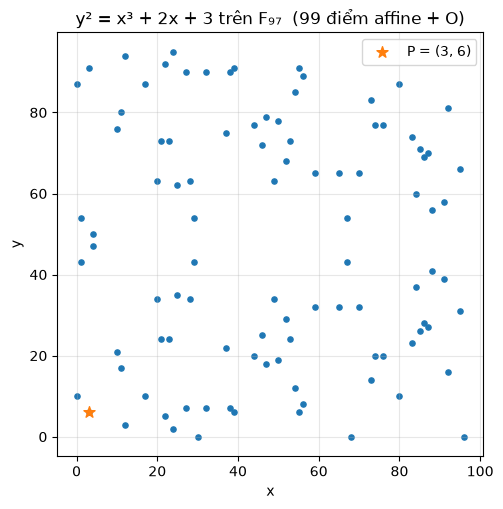

In [9]:
# Trực quan hoá các điểm của E trên F_97 (đồ thị là tập điểm rời rạc)
import matplotlib.pyplot as plt

xs = [pt.x for pt in points]
ys = [pt.y for pt in points]

plt.figure(figsize=(5.5, 5.5))
plt.scatter(xs, ys, s=14)
plt.scatter(P.x, P.y, s=70, marker="*", label=f"P = ({P.x}, {P.y})")
plt.title(f"y² = x³ + 2x + 3 trên F₉₇  ({len(points)} điểm affine + O)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 3c. Chạy thử: đối chiếu `count_points_naive` vs `count_points_bsgs`

**Mục đích:** Xác nhận hai thuật toán cho kết quả `#E` trùng khớp trên các số nguyên tố 14–20 bit, và thử nghiệm đếm điểm bằng BSGS ở kích thước 40 bit.

In [10]:
import time

# Chạy thử 3: so khớp naive và BSGS, đo thời gian
rng = random.Random(42)
for bits in (14, 18, 20):
    p = random_prime(rng, bits)
    E = ECC(rng.randrange(p), rng.randrange(p), p)
    if not E.is_nonsingular():
        continue
    t0 = time.perf_counter(); n1 = count_points_naive(E); t1 = time.perf_counter()
    n2 = count_points_bsgs(E, rng);                       t2 = time.perf_counter()
    w = 2 * isqrt(p) + 2
    print(f"p={p:>8} ({bits} bit) | Hasse: [{p + 1 - w}, {p + 1 + w}] | naive={n1} ({t1 - t0:.3f}s) "
          f"bsgs={n2} ({t2 - t1:.4f}s) | khớp: {n1 == n2}")

# p lớn (40 bit): chỉ BSGS khả thi
p = random_prime(random.Random(7), 40)
E = ECC(12345, 67890, p)
t0 = time.perf_counter(); N = count_points(E); dt = time.perf_counter() - t0
print(f"\np 40-bit = {p}: #E = {N} (BSGS, {dt:.3f}s) | t = p+1-#E = {p + 1 - N}, |t| <= 2√p: {abs(p + 1 - N) <= 2 * isqrt(p) + 2}")

p=   10477 (14 bit) | Hasse: [10272, 10684] | naive=10615 (0.003s) bsgs=10615 (0.0002s) | khớp: True
p=  233879 (18 bit) | Hasse: [232912, 234848] | naive=234048 (0.120s) bsgs=234048 (0.0003s) | khớp: True
p=  753547 (20 bit) | Hasse: [751810, 755286] | naive=752585 (0.466s) bsgs=752585 (0.0004s) | khớp: True

p 40-bit = 655136624683: #E = 655135603569 (BSGS, 0.013s) | t = p+1-#E = 1021115, |t| <= 2√p: True


### 4a. Chạy thử: kiểm tra hàm phân loại `classify`

**Mục đích:** Xác nhận `classify` gán đúng nhãn `anomalous`, `supersingular`, `safe_prime_order`, `cofactor_gt1` và `smooth_order` cho 5 tình huống điển hình.

In [11]:
# Chạy thử 4: phân loại các tình huống điển hình
print(classify(1009, 1009, 1009, 1, {1009: 1}, None), "<- N = p")
print(classify(1009, 1010, 1010, 1, {2: 1, 5: 1, 101: 1}, None), "<- N = p + 1")
print(classify(1009, 1031, 1031, 1, {1031: 1}, None), "<- n nguyên tố, h = 1")
print(classify(1009, 1032, 258, 4, {2: 1, 3: 1, 43: 1}, None), "<- n hợp số, mọi ước < 2^20")
print(classify(1009, 1040, 520, 2, {2: 3, 5: 1, 13: 1}, 16), "<- smooth_bound = 16")

anomalous <- N = p
supersingular <- N = p + 1
safe_prime_order <- n nguyên tố, h = 1
smooth_order <- n hợp số, mọi ước < 2^20
smooth_order <- smooth_bound = 16


### 5a. Chạy thử: sinh một đường cong cho mỗi mode

**Mục đích:** Kiểm tra `generate_curve` với cả 3 chế độ (`prime`, `cofactor`, `smooth`) và in thử cấu trúc JSON đầy đủ của một bản ghi D1.

In [12]:
# Chạy thử 5: một đường cong cho mỗi mode
for mode, bits in (("prime", 20), ("cofactor", 20), ("smooth", 24)):
    row = generate_curve(bits, mode=mode, seed=100 + bits)
    print(f"{mode:<9} p={row['p']:<10} #E={row['E_count']:<10} n={row['subgroup_n']:<10} h={row['cofactor_h']:<3} "
          f"n_factorization={[(f['prime'], f['exponent']) for f in row['n_factorization']]} -> {row['category']}")

print("\nMột bản ghi D1 đầy đủ:")
print(json.dumps(generate_curve(16, "prime", seed=1), indent=2, ensure_ascii=False))

prime     p=1028473    #E=1026581    n=1026581    h=1   n_factorization=[('1026581', 1)] -> safe_prime_order
cofactor  p=14234047   #E=14236726   n=1016909    h=14  n_factorization=[('1016909', 1)] -> cofactor_gt1
smooth    p=9721169    #E=9722882    n=9722882    h=1   n_factorization=[('2', 1), ('13', 1), ('23', 1), ('71', 1), ('229', 1)] -> smooth_order

Một bản ghi D1 đầy đủ:
{
  "curve_id": "crv-00000001",
  "curve_name": null,
  "p": "47569",
  "p_bits": 16,
  "a": "1903",
  "b": "34578",
  "discriminant": "27054",
  "discriminant_ok": true,
  "E_count": "47431",
  "trace_t": "139",
  "E_count_factorization": [
    {
      "prime": "47431",
      "exponent": 1
    }
  ],
  "base_point_x": "14528",
  "base_point_y": "4060",
  "subgroup_n": "47431",
  "n_bits": 16,
  "n_is_prime": true,
  "n_factorization": [
    {
      "prime": "47431",
      "exponent": 1
    }
  ],
  "cofactor_h": "1",
  "largest_prime_factor_n": "47431",
  "is_anomalous": false,
  "is_supersingular": false,
  "

## Bước 7 – Đọc/ghi CSV theo chuẩn D1

CSV chỉ chứa chuỗi, nên cần quy ước:
- Cột JSON (`E_count_factorization`, `n_factorization`, `small_order_available`) → `json.dumps(..., separators=(",",":"))`
- Cột bool → `"true"`/`"false"`
- `None` → ô rỗng
- Số nguyên lớn (`p`, `a`, `b`, `E_count`, …) giữ **dạng chuỗi**, tránh mất chính xác ở công cụ ngoài.

`write_csv(..., append=True)` ghi nối vào file có sẵn; `_next_index` tính chỉ số `curve_id` kế tiếp (`crv-XXXXXXXX`, hex 8 chữ số) khi ghi nối.

### 7a. Chạy thử: kiểm tra đọc/ghi CSV (round-trip)

**Mục đích:** Sinh 3 curve mẫu, ghi ra `../data/D1_roundtrip_test.csv`, đọc lại bằng `load_csv` và kiểm chứng khớp hoàn toàn dữ liệu gốc.

In [13]:
# Chạy thử 7: ghi -> đọc lại -> kiểm chứng (round-trip)
rows = [generate_curve(b, "prime", seed=b) for b in (16, 20, 24)]
write_csv(rows, "../data/D1_roundtrip_test.csv")
back = load_csv("../data/D1_roundtrip_test.csv")

print("Số dòng đọc lại:", len(back))
print("Round-trip khớp (trừ các giá trị None):",
      all(all(r[c] == b[c] for c in D1_COLUMNS) for r, b in zip(rows, back)))
print("verify_row trên dòng CSV đọc lại:", [verify_row(b) for b in back])
print(open("../data/D1_roundtrip_test.csv", encoding="utf-8").read()[:900], "...")

Số dòng đọc lại: 3
Round-trip khớp (trừ các giá trị None): True
verify_row trên dòng CSV đọc lại: [[], [], []]
curve_id,curve_name,p,p_bits,a,b,discriminant,discriminant_ok,E_count,trace_t,E_count_factorization,base_point_x,base_point_y,subgroup_n,n_bits,n_is_prime,n_factorization,cofactor_h,largest_prime_factor_n,is_anomalous,is_supersingular,category,source_for_point_class,small_order_available,generation_method,seed,notes,git_commit,created_at
crv-00000010,,53407,16,21958,43693,4259,true,53149,259,"[{""prime"":""53149"",""exponent"":1}]",9302,16684,53149,16,true,"[{""prime"":""53149"",""exponent"":1}]",1,53149,false,false,safe_prime_order,,,toy_curve_gen.v1,16,mode=prime,ac6dc2d56c51,2026-11-27T06:45:07Z
crv-00000014,,723451,20,211018,303687,665274,true,723493,-41,"[{""prime"":""723493"",""exponent"":1}]",467708,635936,723493,20,true,"[{""prime"":""723493"",""exponent"":1}]",1,723493,false,false,safe_prime_order,,,toy_curve_gen.v1,20,mode=prime,ac6dc2d56c51,2026-11-27T06:45:07Z
crv-

## Bước 8 – Selftest và giao diện dòng lệnh

- `selftest()` chạy 4 nhóm kiểm thử: 
    - (1) naive ≡ BSGS, 
    - (2) phân tích thừa số, 
    - (3) sinh + kiểm chứng đủ 3 mode, 
    - (4) tính tất định theo seed.

- `main(argv)` nhận danh sách tham số như `argparse`.**Trong notebook** ta gọi `main([...])` trực tiếp (`argv` là list chuỗi).
- Mỗi curve dùng `seed = seed_gốc * 1_000_003 + idx` nên các curve độc lập nhưng toàn bộ lô vẫn tái lập được.

### 8a. Chạy selftest kiểm tra toàn bộ module

**Mục đích:** Thực thi `selftest()` để xác nhận đếm điểm, phân tích thừa số, sinh 3 mode đường cong và tính tất định theo seed đều hoạt động chính xác.

In [14]:
# Chạy thử 8: selftest
selftest()

[1] So khớp đếm điểm: naive vs BSGS (p ~ 2^14..2^20)
    p=   14537 #E naive=14410 bsgs=14410 OK
    p=   13313 #E naive=13438 bsgs=13438 OK
    p=   11923 #E naive=11752 bsgs=11752 OK
    p=  108821 #E naive=109303 bsgs=109303 OK
    p=  126601 #E naive=126196 bsgs=126196 OK
    p=  119851 #E naive=119237 bsgs=119237 OK
    p=  738713 #E naive=738755 bsgs=738755 OK
    p=  530203 #E naive=530440 bsgs=530440 OK
    p=  910981 #E naive=910714 bsgs=910714 OK
[2] Phân tích thừa số
    2147483647 = {2147483647: 1} OK
    600851475143 = {71: 1, 839: 1, 1471: 1, 6857: 1} OK
    2999997000003 = {3: 1, 999999000001: 1} OK
[3] Sinh + kiểm chứng curve từng mode
    prime    n_bits=16  p=50513        n=50383        h=1   cat=safe_prime_order  OK
    prime    n_bits=28  p=236158463    n=236157227    h=1   cat=safe_prime_order  OK
    cofactor n_bits=20  p=10667351     n=711181       h=15  cat=cofactor_gt1      OK
    smooth   n_bits=24  p=11843501     n=11840571     h=1   cat=smooth_order      OK


True

## Bước 9 – Chạy mẫu (demo)

### 9a. Dùng như thư viện
```python
row = generate_curve(24, mode="prime", seed=1)
E = curve_from_row(row)
G = base_point_from_row(row, E)
```
**Mục đích:** Kiểm tra trực tiếp `G ∈ E`, `n·G = O` (`is_infinity=True`) và thử giải một ECDLP nhỏ bằng cách vét cạn (*baseline* của Track A).

In [16]:
import time

row = generate_curve(24, mode="prime", seed=1)
E = curve_from_row(row)
G = base_point_from_row(row, E)
n = int(row["subgroup_n"])

print(f"E: y^2 = x^3 + {E.a}x + {E.b}  (mod {E.p})   [{row['category']}]")
print("G =", G, "| G ∈ E:", E.is_on_curve(G.x, G.y))
print("n =", n, f"({row['n_bits']} bit) | n·G =", n * G, "| is_infinity:", (n * G).is_infinity)

# Mô phỏng ECDLP: chọn khoá bí mật d, công khai Q = d·G, rồi vét cạn tìm lại d
d = random.Random(2026).randrange(2, 150_000)   # chọn d nhỏ để vét cạn chạy nhanh trong notebook
Q = d * G
t0 = time.perf_counter()
R, k = G, 1
while R != Q:
    R, k = R + G, k + 1
print(f"Vét cạn: tìm được d = {k} (đúng: {d}) sau {time.perf_counter() - t0:.2f}s -> khớp: {k == d}")

E: y^2 = x^3 + 2771238x + 11765570  (mod 14623261)   [safe_prime_order]
G = Point(7797686, 671944) | G ∈ E: True
n = 14626093 (24 bit) | n·G = Point(Infinity) | is_infinity: True
Vét cạn: tìm được d = 31228 (đúng: 31228) sau 0.07s -> khớp: True


### 9b. Sinh trọn bộ dữ liệu D1 (`--full-d1`)

**Mục đích:** Chạy `main(["--full-d1", "--out", ...])` để sinh đầy đủ **53 đường cong D1** (gồm `safe_prime_order`, `smooth_order`, `cofactor_gt1`, `anomalous`, `supersingular`, invalid-curve components và 2 đường cong chuẩn `standard_named`) và ghi ra `data/D1_curves.csv`. Tương đương lệnh CLI:
```bash
python curves/toy_curve_gen.py --full-d1 --out data/D1_curves.csv
```

In [18]:
args = [
    "--full-d1",
    "--out", str(ROOT_DIR / "data" / "D1_curves.csv"),
]
rc = main(args)
print("mã trả về:", rc)

Đã ghi trọn bộ 53 curve D1 -> /home/han-sui/ECC-Cryptanalysis/data/D1_curves.csv
mã trả về: 0


### 9c. Đọc lại, kiểm chứng đầy đủ và thống kê

**Mục đích:** Nạp lại `data/D1_curves.csv` bằng `load_csv`, chạy `verify_row` trên từng đường cong (bật `recount=True` với các toy curve có `p_bits <= 42`, tắt recount cho `standard_named` 256-bit) và in thống kê phân bố `category`.

In [20]:
from collections import Counter

rows = load_csv(str(ROOT_DIR / "data" / "D1_curves.csv"))
print(f"{'curve_id':<14}{'category':<25}{'p_bits':<7}{'n_bits':<7}{'h':<5}{'lỗi'}")
for r in rows:
    p_bits = int(r["p"]).bit_length()
    can_recount = (r["category"] != "standard_named") and (p_bits <= 42)
    errs = verify_row(r, recount=can_recount)
    print(f"{r['curve_id']:<14}{r['category']:<25}{p_bits:<7}{r['n_bits']:<7}{r['cofactor_h']:<5}{errs or 'OK'}")

print("\nThống kê category:", dict(Counter(r["category"] for r in rows)))

curve_id      category                 p_bits n_bits h    lỗi
crv-00000001  safe_prime_order         16     16     1    OK
crv-00000002  safe_prime_order         18     18     1    OK
crv-00000003  safe_prime_order         20     20     1    OK
crv-00000004  safe_prime_order         22     22     1    OK
crv-00000005  safe_prime_order         24     24     1    OK
crv-00000006  safe_prime_order         26     26     1    OK
crv-00000007  safe_prime_order         28     28     1    OK
crv-00000008  safe_prime_order         30     30     1    OK
crv-00000009  safe_prime_order         32     32     1    OK
crv-0000000a  safe_prime_order         34     34     1    OK
crv-0000000b  safe_prime_order         36     36     1    OK
crv-0000000c  safe_prime_order         38     38     1    OK
crv-0000000d  safe_prime_order         40     40     1    OK
crv-0000000e  smooth_order             16     16     1    OK
crv-0000000f  smooth_order             20     20     1    OK
crv-00000010  smooth_or

### 9d. Kiểm tra "phát hiện lỗi"

**Mục đích:** Chứng minh bộ kiểm chứng `verify_row` **thật sự bắt được dữ liệu sai** bằng cách cố tình sửa sai `subgroup_n`, `base_point_y` và `E_count` trên một bản ghi 20-bit hợp lệ.

In [21]:
good = generate_curve(20, "prime", seed=5)
print("Bản ghi gốc          :", verify_row(good))

bad1 = dict(good); bad1["subgroup_n"] = str(int(good["subgroup_n"]) + 2)
print("Sửa n + 2            :", verify_row(bad1, recount=False))

bad2 = dict(good); bad2["base_point_y"] = str((int(good["base_point_y"]) + 1) % int(good["p"]))
print("Sửa tung độ của G    :", verify_row(bad2, recount=False))

bad3 = dict(good); bad3["E_count"] = str(int(good["E_count"]) + 1)
print("Sửa #E               :", verify_row(bad3, recount=False))

Bản ghi gốc          : []
Sửa n + 2            : ['n*G != O', 'n_factorization không nhân lại ra n', 'n * h != #E']
Sửa tung độ của G    : ['G không nằm trên curve', 'n*G != O']
Sửa #E               : ['E_count_factorization không nhân lại ra #E', 'n * h != #E']


### 9e. Chi phí đếm điểm theo số bit – naive $O(p)$ so với BSGS $\approx O(p^{1/4})$

**Mục đích:** Đo thời gian thực tế và vẽ biểu đồ thang logarit so sánh `count_points_naive` ($O(p)$) với `count_points_bsgs` ($\approx O(p^{1/4})$) khi kích thước $p$ tăng từ 12 đến 22 bit.

12 bit | naive   0.0010s | bsgs   0.0001s
14 bit | naive   0.0035s | bsgs   0.0001s
16 bit | naive   0.0243s | bsgs   0.0003s
18 bit | naive   0.1094s | bsgs   0.0003s
20 bit | naive   0.6224s | bsgs   0.0004s
22 bit | naive   2.2947s | bsgs   0.0005s


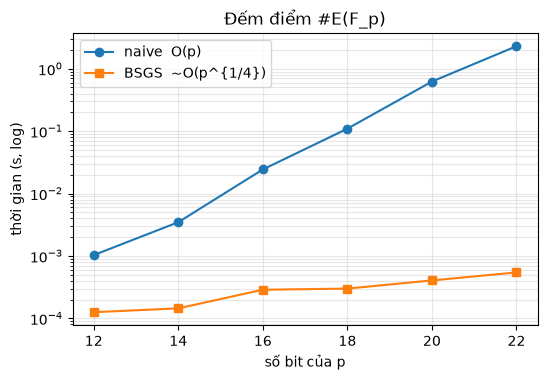

In [23]:
import time
import matplotlib.pyplot as plt

rng = random.Random(99)
bits_list, t_naive, t_bsgs = [], [], []
for bits in (12, 14, 16, 18, 20, 22):
    p = random_prime(rng, bits)
    E = ECC(rng.randrange(p), rng.randrange(p), p)
    if not E.is_nonsingular():
        continue
    t0 = time.perf_counter(); a = count_points_naive(E); t1 = time.perf_counter()
    b = count_points_bsgs(E, rng);                       t2 = time.perf_counter()
    assert a == b
    bits_list.append(bits); t_naive.append(t1 - t0); t_bsgs.append(t2 - t1)
    print(f"{bits:>2} bit | naive {t1 - t0:8.4f}s | bsgs {t2 - t1:8.4f}s")

plt.figure(figsize=(6, 3.8))
plt.semilogy(bits_list, t_naive, "o-", label="naive  O(p)")
plt.semilogy(bits_list, t_bsgs, "s-", label="BSGS  ~O(p^{1/4})")
plt.xlabel("số bit của p"); plt.ylabel("thời gian (s, log)"); plt.grid(alpha=.3, which="both"); plt.legend()
plt.title("Đếm điểm #E(F_p)")
plt.show()

## Tổng kết

**Đã có:** module sinh curve tất định theo seed, đếm điểm nhanh, phân loại các nhóm bảo mật, kiểm chứng toán học, đọc/ghi CSV chuẩn D1 (29 cột) kế thừa từ `curves/ecc.py` và `curves/toy_curve_gen.py`.

**Gắn với checklist Thành viên A:**
- **T2** `curves/toy_curve_gen.py` là file chạy chính; notebook này dùng để giải thích, kiểm thử từng phần và demo.
- **T3** sinh `data/D1_curves.csv` (53 đường cong, mọi category) → chạy `main(["--full-d1", ...])` ở mục 9b; các script `exhaustive_search.py`, `bsgs.py`, `pollard_rho.py` đọc D1 qua `load_csv`.
- **T4** `gen_smooth_curves.py` tái sử dụng `generate_curve(..., mode="smooth")`.

**Lưu ý kỹ thuật khi tiến tới đo hiệu năng**
- Python thuần chỉ phù hợp tới ~42–48 bit cho đếm điểm (`count_points_bsgs`).
- Miller–Rabin tất định chỉ đảm bảo tới $\approx3{,}3\times10^{24}$ (đủ cho toy curve).
- Đường cong sinh ra **không** dành cho mật mã thực tế.

---

## Tài liệu tham khảo

**Đã tra cứu trực tuyến trong phiên này**
1. R. Schoof, *Counting points on elliptic curves over finite fields*, J. Théor. Nombres Bordeaux 7(1), 1995, tr. 219–254 – mô tả thuật toán BSGS đếm điểm và mẹo Mestre. <https://eudml.org/doc/93624>
2. J. Cremona, A. Sutherland, *On a theorem of Mestre and Schoof* – tính duy nhất của $\#E$ khi $q>229$ qua đường cong xoắn. <https://arxiv.org/pdf/0901.0120>
3. A. Sutherland, *MIT 18.783 Elliptic Curves, Lecture 7* – định lý Hasse, thuật toán Shanks/Mestre, bảng so sánh độ phức tạp các cách đếm điểm. <https://math.mit.edu/classes/18.783/2025/LectureSlides7.pdf>
4. Wikipedia, *Counting points on elliptic curves* (tổng quan: naive, BSGS, Schoof, SEA). <https://en.wikipedia.org/wiki/Counting_points_on_elliptic_curves>
5. Wikipedia, *Schoof's algorithm*. <https://en.wikipedia.org/wiki/Schoof%27s_algorithm>
6. Stanford PBC, *Counting Points* (định lý Hasse, vết Frobenius). <https://crypto.stanford.edu/pbc/notes/elliptic/count.html>
7. L. Chen, D. Moody, K. Randall, A. Regenscheid, A. Robinson, *NIST SP 800-186: Recommendations for Discrete Logarithm-based Cryptography: Elliptic Curve Domain Parameters*, 2023. <https://doi.org/10.6028/NIST.SP.800-186> (công bố cùng FIPS 186-5)

**Tài liệu chuẩn khác**
- NIST **FIPS 186-5** *Digital Signature Standard* (2023); IETF **RFC 6090** *Fundamental Elliptic Curve Cryptography Algorithms* – hai mục này cũng nằm trong task "Rà soát NIST SP 800-186, RFC 6090, FIPS 186-5" của checklist.
- D. Hankerson, A. Menezes, S. Vanstone, *Guide to Elliptic Curve Cryptography*, Springer, 2004.
- L. Washington, *Elliptic Curves: Number Theory and Cryptography*, 2nd ed., CRC Press, 2008.
- J. Silverman, *The Arithmetic of Elliptic Curves*, Springer.
- Với mục tiêu Track A: Pohlig–Hellman (1978), Pollard (1978) *Monte Carlo methods for index computation (mod p)*, Smart (1999) và Semaev/Satoh–Araki (1998) cho đường cong anomalous.